# Task 3 · How reliable are TGLF surrogate fluxes?
We use five independently initialized neural networks to predict electron heat flux, ion heat flux and electron particle flux in the supplied gyro-Bohm units. We test their error bars first on held-out scan cases, then outside the scan and finally around a measured DIII-D plasma.

**Run this notebook** with Python, NumPy, pandas, SciPy, scikit-learn and Matplotlib. Place the three archives named below beside it or in an `upload/` subfolder. The Task 1 SAT3 archive is background material. All training labels here come from the Task 2 SAT2 scan. The supplied scan has no saved network or original split assignments, so this reconstruction uses a reproducible 70/15/15 split. Its scores apply to that split.

In [1]:
from pathlib import Path
import tarfile
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from threadpoolctl import threadpool_limits

features = 'RLTS_1 RLTS_2 RLNS_1 TAUS_2 XNUE Q_LOC Q_PRIME_LOC KAPPA_LOC DRMAJDX_LOC RMIN_LOC MASS_2'.split()
targets = ['Q_e', 'Q_i', 'Gamma_e']
def read_scan(name):
    path = Path(name + '.tar.gz')
    if not path.exists():
        path = Path('upload') / path
    rows = {}
    with tarfile.open(path, 'r|gz') as archive:
        for member in archive:
            folder, _, file = member.name.rpartition('/')
            if file not in ('input.tglf.gen', 'out.tglf.gbflux'):
                continue
            raw = archive.extractfile(member).read().decode()
            row = rows.setdefault(folder, {})
            if file == 'input.tglf.gen':
                settings = {p[1]: p[0] for line in raw.splitlines() if len(p := line.split()) == 2}
                assert float(settings['RLNS_1']) == float(settings['RLNS_2'])
                row.update({k: float(settings[k]) for k in features})
            else:
                gamma_e, gamma_i, qe, qi, *_ = map(float, raw.split())
                row.update(Q_e=qe, Q_i=qi, Gamma_e=gamma_e)
    df = pd.DataFrame.from_dict(rows, orient='index').sort_index()
    assert np.isfinite(df[features + targets]).all().all()
    return df

scan = read_scan('scan_db')
outside = read_scan('scan_db_outside')
d3d = read_scan('data_d3d')
ref = d3d.loc[d3d.index.str.contains('/d3d_db/')].iloc[0]
runs = d3d.loc[d3d.index.str.contains('/d3d_uq/')]
assert (len(scan), len(outside), len(runs)) == (5000, 270, 300)
print('DIII-D reference (appendix flux ordering):')
print(ref[targets].to_string())

DIII-D reference (appendix flux ordering):
Q_e        3.62970
Q_i        4.30890
Gamma_e    0.38696


## 1 · Fit the ensemble and calibrate its intervals
Each member has two 64-unit ReLU layers and predicts all three fluxes. Scaling uses training cases only. Early stopping uses an internal subset of the training partition. The separate validation partition calibrates a two-sided interval for each output. Its half-width is proportional to member disagreement plus a small training-derived floor. The floor keeps nearly unanimous predictions from receiving a zero-width interval. The calibration rank targets 90% marginal coverage for each flux on exchangeable cases.

In [2]:
train, hold = train_test_split(scan, test_size=0.30, random_state=42)
val, test = train_test_split(hold, test_size=0.50, random_state=42)
sx = StandardScaler().fit(train[features])
sy = StandardScaler().fit(train[targets])
x, y = sx.transform(train[features]), sy.transform(train[targets])
models = []
with threadpool_limits(limits=1):
    for seed in range(5):
        net = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=600, early_stopping=True,
                           n_iter_no_change=25, random_state=seed)
        models.append(net.fit(x, y))

def ensemble(frame):
    x = sx.transform(frame[features])
    with threadpool_limits(limits=1):
        members = np.stack([sy.inverse_transform(net.predict(x)) for net in models])
    return members.mean(axis=0), members.std(axis=0, ddof=1)

floor = 0.02 * sy.scale_
mu, sd = ensemble(val)
scores = np.abs(val[targets].to_numpy() - mu) / (sd + floor)
rank = int(np.ceil(0.90 * (len(val) + 1)))
factor = np.sort(scores, axis=0)[rank - 1]
def predict(frame):
    mean, sd = ensemble(frame)
    half = factor * (sd + floor)
    return mean, mean - half, mean + half
print('Train / calibration / test:', len(train), len(val), len(test))

Train / calibration / test: 3500 750 750


## 2 · Do the error bars work on held-out cases?
Coverage counts the fraction of TGLF values inside the interval. The scatterplots compare interval half-width with absolute error, in the same units. Orange points summarize equal-count uncertainty bins. Spearman correlation measures whether larger error bars tend to accompany larger errors.

            MAE  mean half-width  coverage  rank correlation
Q_e       9.353           18.813     0.897             0.480
Q_i      11.084           21.810     0.892             0.519
Gamma_e   2.753            5.873     0.931             0.547


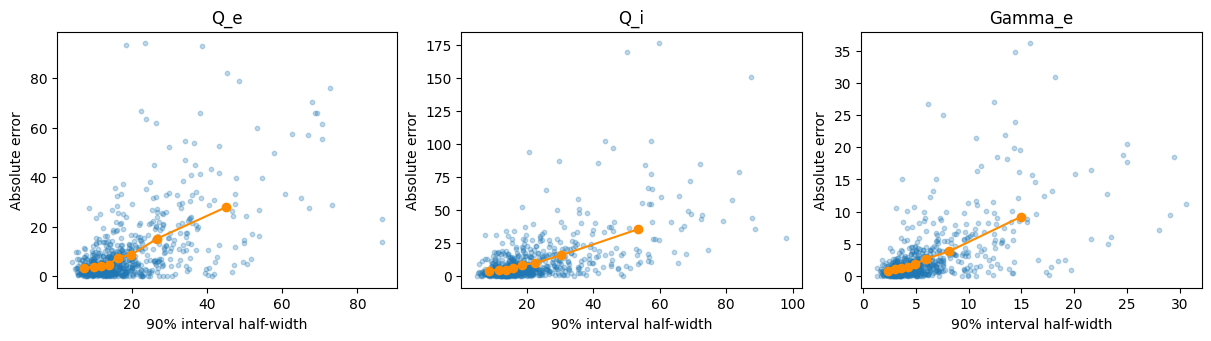

In [3]:
def diagnostics(frame):
    mean, lo, hi = predict(frame)
    truth = frame[targets].to_numpy()
    err, half = abs(mean - truth), (hi - lo) / 2
    summary = pd.DataFrame({'MAE': err.mean(0), 'mean half-width': half.mean(0),
                            'coverage': ((truth >= lo) & (truth <= hi)).mean(0)}, index=targets)
    return summary, err, half

baseline, err, half = diagnostics(test)
baseline['rank correlation'] = [spearmanr(err[:,j], half[:,j]).statistic for j in range(3)]
print(baseline.round(3).to_string())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for j, ax in enumerate(axes):
    ax.scatter(half[:,j], err[:,j], s=10, alpha=0.28)
    bins = np.array_split(np.argsort(half[:,j]), 8)
    ax.plot([half[b,j].mean() for b in bins], [err[b,j].mean() for b in bins], 'o-', color='darkorange')
    ax.set(title=targets[j], xlabel='90% interval half-width', ylabel='Absolute error')
plt.show()

To locate uncertain regions, group each test input into quartiles (or individual isotope masses). For each flux, rank groups by their mean half-width relative to the overall test mean. These one-input summaries can overlap and do not establish causality.

In [4]:
regions = []
for feature in features:
    values = test[feature].reset_index(drop=True)
    groups = values if values.nunique() <= 4 else pd.qcut(values, 4, duplicates='drop')
    for label, idx in values.groupby(groups, observed=True).groups.items():
        for j, flux in enumerate(targets):
            regions.append([flux, feature, str(label), len(idx), half[idx,j].mean()/half[:,j].mean()])
regions = pd.DataFrame(regions, columns=['flux', 'input', 'region', 'n', 'width / test mean'])
print(regions.sort_values('width / test mean', ascending=False).groupby('flux').head(3)
      .sort_values('flux').round(2).to_string(index=False))

   flux       input                         region   n  width / test mean
Gamma_e        XNUE (0.009000000000000001, 0.0315] 188               1.48
Gamma_e      RLNS_1                 (2.533, 2.998] 188               1.30
Gamma_e DRMAJDX_LOC               (-0.501, -0.387] 188               1.18
    Q_e        XNUE (0.009000000000000001, 0.0315] 188               1.39
    Q_e   KAPPA_LOC                   (1.751, 2.0] 188               1.20
    Q_e DRMAJDX_LOC               (-0.501, -0.387] 188               1.20
    Q_i        XNUE (0.009000000000000001, 0.0315] 188               1.38
    Q_i      RLTS_2                   (3.014, 3.5] 188               1.23
    Q_i DRMAJDX_LOC               (-0.501, -0.387] 188               1.20


## 3 · Does ensemble disagreement warn about extrapolation?
Each group moves one input beyond the prescribed scan range. Compare its mean absolute error and mean interval half-width with the corresponding test values. A ratio above one means growth. Coverage measures whether that growth was sufficient.

In [5]:
records = []
groups = outside.index.str.extract(r'(ood_[^/]+)', expand=False)
for group, frame in outside.groupby(groups):
    assert len(frame) == 30
    stats, _, _ = diagnostics(frame)
    records.append(stats.assign(group=group, error_ratio=stats.MAE/baseline.MAE,
                                width_ratio=stats['mean half-width']/baseline['mean half-width']))
ood = pd.concat(records).rename_axis('flux').reset_index()
print(ood.pivot(index='group', columns='flux', values=['error_ratio','width_ratio','coverage'])
      .round(2).to_string())
print('Pooled outside results')
print(diagnostics(outside)[0].round(3).to_string())

                error_ratio             width_ratio             coverage            
flux                Gamma_e   Q_e   Q_i     Gamma_e   Q_e   Q_i  Gamma_e   Q_e   Q_i
group                                                                               
ood_DRMAJDX_LOC        3.51  2.95  2.67        1.90  1.84  2.01     0.63  0.77  0.77
ood_KAPPA_LOC          2.46  2.67  2.66        1.70  1.80  1.83     0.80  0.77  0.77
ood_Q_LOC              4.41  3.20  4.14        2.46  2.28  2.49     0.80  0.87  0.83
ood_RLN                5.30  3.06  2.67        2.55  2.05  2.19     0.80  0.83  0.93
ood_RLTS_1             1.91  2.81  1.57        1.53  1.79  1.47     0.77  0.77  0.90
ood_RLTS_2             2.46  1.85  4.55        1.62  1.54  2.03     0.83  0.80  0.60
ood_RMIN_LOC           1.81  1.63  1.49        2.04  1.85  1.89     0.90  0.87  0.93
ood_TAUS_2             2.43  2.54  4.17        1.78  1.84  1.99     0.87  0.80  0.73
ood_XNUE               2.27  1.52  2.09        1.49  1.52  1.32  

## 4 · Propagate DIII-D measurement uncertainty
Read the nominal settings directly from the reference run. Draw independent uniform perturbations within the stated percentage bounds. One shared density-gradient input represents both species. Geometry and isotope remain fixed except for the two specified safety-factor inputs. Each draw contributes its ensemble mean, so the distribution isolates the propagation of input uncertainty. Compare it with both the 300 TGLF runs and surrogate predictions at those exact inputs.

Nominal case
            Q_e    Q_i  Gamma_e
TGLF      3.630  4.309    0.387
ensemble  3.087  7.022    0.024
10,000 draws and five-model prediction: 0.074 seconds (training excluded).
   flux                sample   mean    SD  SD / |mean| (%)    p05  median   p95
    Q_e         10k surrogate  3.127 0.985           31.494  1.556   3.103 4.768
    Q_e 300 matched surrogate  3.161 0.945           29.895  1.512   3.208 4.676
    Q_e              300 TGLF  4.120 1.105           26.818  2.478   3.965 6.172
    Q_i         10k surrogate  7.041 1.483           21.063  4.598   7.062 9.452
    Q_i 300 matched surrogate  7.010 1.550           22.108  4.488   6.998 9.332
    Q_i              300 TGLF  4.436 1.120           25.248  2.610   4.358 6.361
Gamma_e         10k surrogate -0.048 0.349          731.971 -0.645  -0.036 0.498
Gamma_e 300 matched surrogate -0.017 0.339         2019.808 -0.601  -0.011 0.487
Gamma_e              300 TGLF  0.483 0.236           48.814  0.136   0.472 0.908


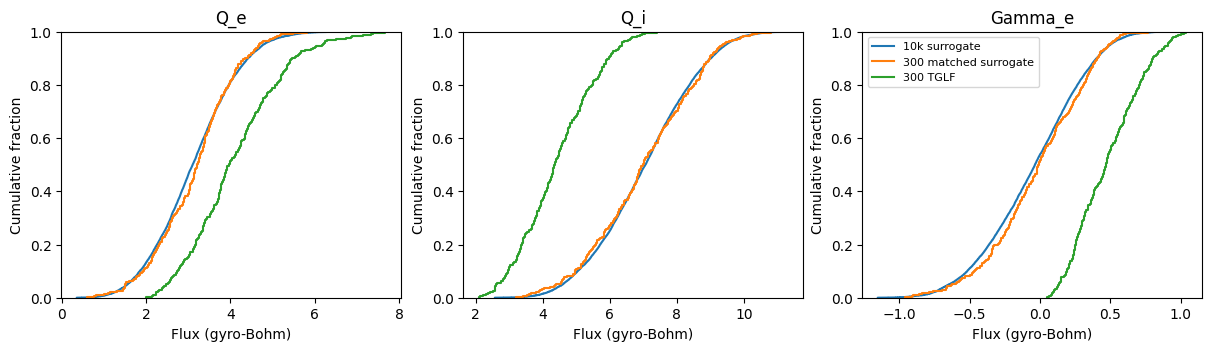

In [6]:
fractions = dict(RLTS_1=.10, RLTS_2=.10, RLNS_1=.10, TAUS_2=.10, XNUE=.20,
                 Q_LOC=.05, Q_PRIME_LOC=.10)
rng = np.random.default_rng(2026)
n = 10_000
start = perf_counter()
nominal = pd.DataFrame(np.tile(ref[features], (n,1)), columns=features)
draws = nominal.copy()
for feature, frac in fractions.items():
    draws[feature] *= rng.uniform(1-frac, 1+frac, n)
mc, _ = ensemble(draws)
seconds = perf_counter() - start
matched, _ = ensemble(runs)
central, _ = ensemble(ref.to_frame().T)
print('Nominal case')
print(pd.DataFrame([ref[targets].values, central[0]], index=['TGLF','ensemble'], columns=targets).round(3))
print(f'{n:,} draws and five-model prediction: {seconds:.3f} seconds (training excluded).')
truth = runs[targets].to_numpy()
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
for j, ax in enumerate(axes):
    for label, data in [('10k surrogate', mc), ('300 matched surrogate', matched), ('300 TGLF', truth)]:
        a = data[:,j]
        rows.append([targets[j], label, a.mean(), a.std(ddof=1), 100*a.std(ddof=1)/abs(a.mean()),
                     *np.quantile(a, [.05,.50,.95])])
        ax.ecdf(a, label=label)
    ax.set(title=targets[j], xlabel='Flux (gyro-Bohm)', ylabel='Cumulative fraction')
axes[-1].legend(fontsize=8)
plt.show()
summary = pd.DataFrame(rows, columns=['flux','sample','mean','SD','SD / |mean| (%)','p05','median','p95'])
print(summary.round(3).to_string(index=False))

### Which measurement drives each flux?
Vary one measured input at a time using the same draws and fix all others at the reference. Rank inputs by the resulting flux standard deviation. These local sensitivities omit interactions, so their standard deviations need not add up to the joint spread.

In [7]:
sensitivity = {}
for feature in fractions:
    single = nominal.copy()
    single[feature] = draws[feature]
    pred, _ = ensemble(single)
    sensitivity[feature] = pred.std(axis=0, ddof=1)
oat = pd.DataFrame(sensitivity, index=targets).T
print(oat.round(4).to_string())
print('Largest contribution by flux:')
print(oat.idxmax().to_string())

                Q_e     Q_i  Gamma_e
RLTS_1       0.1270  0.8931   0.1246
RLTS_2       0.3141  1.1955   0.1745
RLNS_1       0.6502  0.2637   0.2701
TAUS_2       0.2063  0.1105   0.0476
XNUE         0.5224  0.4352   0.0766
Q_LOC        0.1770  0.1463   0.0392
Q_PRIME_LOC  0.0480  0.1508   0.0157
Largest contribution by flux:
Q_e        RLNS_1
Q_i        RLTS_2
Gamma_e    RLNS_1


## What the runs show

**Inside the scan.** The nominal 90% intervals covered 89.7% of electron heat fluxes, 89.2% of ion heat fluxes and 93.1% of electron particle fluxes. Larger half-widths tended to flag larger errors, with rank correlations of 0.48–0.55. The lowest collisionality quartile (XNUE up to 0.0315) had the widest average intervals for every flux, 38–48% above its respective test mean.

**Outside the scan.** Average intervals widened in every group, but pooled coverage fell to 81–83%. The high ion-temperature-gradient scan is a concrete failure case. Ion heat flux error grew 4.55-fold while interval width only doubled, covering 18 of 30 runs. Ensemble disagreement gives a warning at the group level, but the in-range calibration understates extrapolation risk.

**Around the DIII-D reference.** With the specified mixed input error bars, the 10,000 surrogate draws gave electron and ion heat-flux standard deviations of 0.99 and 1.48 (31% and 21% of their means). Both TGLF standard deviations were close to 1.1. The surrogate's particle-flux SD was 0.35 versus 0.24 for TGLF. Its predicted mean was near zero, making relative particle-flux spread misleading.

**Distribution agreement.** On the same 300 inputs, the ensemble underestimated the electron heat-flux 95th percentile (4.68 versus 6.17) and overestimated the ion heat-flux 95th percentile (9.33 versus 6.36). It predicted a slightly negative median particle flux versus +0.47 for TGLF. These discrepancies persist when the inputs are paired, so drawing more surrogate samples alone cannot resolve them.

**Local sensitivity.** Within the surrogate, the shared density gradient produced the largest one-at-a-time spread in electron heat and particle flux. The ion temperature gradient dominated ion heat flux. These rankings describe the fitted model near this plasma. The 300 joint TGLF runs provide a distribution check, not an independent one-at-a-time ranking.